# Lab 10 — Deep Reinforcement Learning on `highway-env`

**ELEC5308: Intelligent Information Engineering Practice**


> **This notebook is fully self-contained.** Every helper function (environment setup, training
> wrappers, evaluation, GIF/MP4 recording, plotting, results I/O) is defined directly in the cells
> below — there is no separate Python package to install or path to configure. The **only** install
> you need is the one `%pip install` cell at the top, for the external RL libraries themselves
> (`gymnasium`, `highway-env`, `stable-baselines3`, `torch`).


> ⚠️ **Mandatory task time budget: 30 minutes.** The "Mandatory Task" section (Steps 2–5 below) is
> designed to fit that budget on a CPU laptop. "Optional Extensions" at the end is **ungraded**
> take-home material — do not start it until the mandatory task's artefacts are saved.

> ✍️ **AI Journal reminder:** log any significant Copilot/ChatGPT/Claude interaction you use while
> completing this notebook, per the course AI Usage Policy.


## Step 0 — Install and import

**Install just once per machine/Colab session** — if you re-run this notebook later in the same
session, skip straight to the imports cell.

In [4]:
import importlib.util

# `find_spec` raises when a dotted module's parent package is absent.
try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError as exc:
    if exc.name not in {"google", "google.colab"}:
        raise
    IN_COLAB = False

if IN_COLAB:
    # Colab already ships torch/numpy/pandas/matplotlib/opencv -- only install what's missing.
    %pip install -q "gymnasium" "highway-env" "stable-baselines3"
else:
    # Fresh local venv: install everything. CPU-only torch keeps this install smaller/faster
    # than the default (CUDA) wheel -- you do not need a GPU for this lab.
    %pip install -q "gymnasium" "highway-env" "stable-baselines3" \
        "torch" \
        "opencv-python-headless" "pillow" "matplotlib" "numpy" "pandas"

print("Install complete.")


Note: you may need to restart the kernel to use updated packages.
Install complete.


In [5]:
import sys, os, json, time
import numpy as np
import matplotlib
matplotlib.use("Agg" if IN_COLAB else matplotlib.get_backend())
import matplotlib.pyplot as plt
from PIL import Image

import gymnasium as gym
import highway_env  # noqa: F401  (import registers highway-env's Gym environments)
from stable_baselines3 import DQN, PPO
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback
import torch

print("Python:", sys.version.split()[0])
print("gymnasium:", gym.__version__, "| torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())


Python: 3.14.3
gymnasium: 1.3.0 | torch: 2.13.0 | CUDA available: False


objc[3613]: Class SDLApplication is implemented in both /Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x10e4a4a68) and /Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x178b28890). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[3613]: Class SDLAppDelegate is implemented in both /Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x10e4a4ab8) and /Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x178b288e0). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[3613]: Class SDLTranslatorResponder is implemented in both /Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-pac

---
## Library code (run once, top to bottom)

The cells below are the "library" living directly in this notebook so there is nothing to install or
import-path-configure. **Run every cell in this section once, in order**, before jumping to
"Mandatory Task" below. You only need to **edit** the one cell marked `TODO`.


### `diagnostics` — secondary-signal metrics (MANDATORY — implement this)

Lecture reference: *"The Golden Rule of Diagnostics"* (slide 51) and *"Reading a Training Curve"*
(slide 52):

> "Never read reward in isolation. Always pair raw reward with a secondary signal."

An "episode record" is a `dict` with the keys produced by the `rollout(...)` function defined later
in this notebook:

```
reward   : float  -- total return for the episode
length   : int    -- number of environment steps taken before termination
crashed  : bool   -- True if the episode ended in a collision (highway-env's info["crashed"])
```

Implement the three functions below so that the **self-check cell right after this one** prints
`ALL CHECKS PASSED`. Do not change the function signatures or remove the
`AUTOGRADER_EXTRACT_START` / `AUTOGRADER_EXTRACT_END` comment markers — the autograder locates this
exact cell by those markers to run its own hidden test suite against your implementation.


In [9]:
# === AUTOGRADER_EXTRACT_START: diagnostics ===

def collision_rate(episodes):
    """Return the fraction of episodes in which the agent crashed.

    Parameters
    ----------
    episodes : sequence of dict
        Each dict has a boolean "crashed" field.

    Returns
    -------
    float in [0.0, 1.0]. Return 0.0 for an empty sequence (do not raise or return NaN).
    """
    if not episodes:
        return 0.0
    return sum(bool(episode["crashed"]) for episode in episodes) / len(episodes)


def success_rate(episodes):
    """Return the fraction of episodes that ended WITHOUT a collision.

    This is the complement of collision_rate, but implement it directly (do not just
    return 1 - collision_rate(...) -- the hidden autograder tests check both functions
    separately so a bug in one is not masked by the other).

    Returns
    -------
    float in [0.0, 1.0]. Return 0.0 for an empty sequence.
    """
    if not episodes:
        return 0.0
    return sum(not bool(episode["crashed"]) for episode in episodes) / len(episodes)


def mean_survival_steps(episodes):
    """Return the mean of the "length" field across all episodes.

    Returns
    -------
    float. Return 0.0 for an empty sequence.
    """
    if not episodes:
        return 0.0
    return sum(float(episode["length"]) for episode in episodes) / len(episodes)


def summarize_rollout(episodes):
    """Aggregate per-episode records into one summary dict. Provided -- not a TODO.
    This is what results.json is built from; it will work once the three functions
    above are implemented correctly."""
    n = len(episodes)
    mean_reward = (sum(float(e["reward"]) for e in episodes) / n) if n else 0.0
    return {
        "n_episodes": n,
        "mean_reward": mean_reward,
        "collision_rate": collision_rate(episodes),
        "success_rate": success_rate(episodes),
        "mean_survival_steps": mean_survival_steps(episodes),
    }

# === AUTOGRADER_EXTRACT_END: diagnostics ===


#### Self-check — run this until it prints `ALL CHECKS PASSED`

These are the same categories of test the autograder's **hidden** suite uses on different fixtures
— passing all of these is a strong (not guaranteed-identical) signal you will pass that component
too.


In [11]:
def _check(name, condition):
    status = "PASS" if condition else "FAIL"
    print(f"  [{status}] {name}")
    return condition


def run_diagnostics_self_check():
    import math

    empty = []
    mixed = [
        {"reward": 10.0, "length": 30, "crashed": False},
        {"reward": -5.0, "length": 12, "crashed": True},
        {"reward": 8.0, "length": 30, "crashed": False},
        {"reward": -2.0, "length": 5, "crashed": True},
    ]
    all_safe = [
        {"reward": 9.0, "length": 30, "crashed": False},
        {"reward": 11.0, "length": 25, "crashed": False},
    ]
    all_crashed = [
        {"reward": -1.0, "length": 3, "crashed": True},
        {"reward": -1.0, "length": 7, "crashed": True},
        {"reward": -1.0, "length": 2, "crashed": True},
    ]

    results = []
    results.append(_check("collision_rate([]) == 0.0", collision_rate(empty) == 0.0))
    results.append(_check("collision_rate(mixed) == 0.5", math.isclose(collision_rate(mixed), 0.5)))
    results.append(_check("collision_rate(all_safe) == 0.0", collision_rate(all_safe) == 0.0))
    results.append(_check("collision_rate(all_crashed) == 1.0", collision_rate(all_crashed) == 1.0))

    results.append(_check("success_rate([]) == 0.0", success_rate(empty) == 0.0))
    results.append(_check("success_rate(mixed) == 0.5", math.isclose(success_rate(mixed), 0.5)))
    results.append(_check("success_rate(all_safe) == 1.0", success_rate(all_safe) == 1.0))
    results.append(_check("success_rate(all_crashed) == 0.0", success_rate(all_crashed) == 0.0))
    results.append(_check(
        "success_rate + collision_rate == 1.0 (mixed/all_safe/all_crashed)",
        all(math.isclose(success_rate(e) + collision_rate(e), 1.0) for e in (mixed, all_safe, all_crashed)),
    ))

    results.append(_check("mean_survival_steps([]) == 0.0", mean_survival_steps(empty) == 0.0))
    results.append(_check("mean_survival_steps(mixed) == 19.25", math.isclose(mean_survival_steps(mixed), 19.25)))
    results.append(_check(
        "mean_survival_steps(constant length=10) == 10.0",
        math.isclose(mean_survival_steps([{"reward": 0.0, "length": 10, "crashed": False}] * 5), 10.0),
    ))

    summary = summarize_rollout(mixed)
    expected_keys = {"n_episodes", "mean_reward", "collision_rate", "success_rate", "mean_survival_steps"}
    results.append(_check("summarize_rollout keys present", expected_keys <= summary.keys()))
    results.append(_check("summarize_rollout values correct", (
        summary["n_episodes"] == 4
        and math.isclose(summary["mean_reward"], (10.0 - 5.0 + 8.0 - 2.0) / 4)
        and math.isclose(summary["collision_rate"], 0.5)
        and math.isclose(summary["success_rate"], 0.5)
        and math.isclose(summary["mean_survival_steps"], 19.25)
    )))
    results.append(_check("summarize_rollout([]) all zero", all(
        v == 0 for k, v in summarize_rollout(empty).items() if k != "n_episodes"
    )))

    if all(results):
        print(f"\nALL CHECKS PASSED ({sum(results)}/{len(results)})")
    else:
        print(f"\n{sum(results)}/{len(results)} checks passed -- fix the failing ones above before continuing.")
    return all(results)


assert run_diagnostics_self_check(), "Fix diagnostics.py logic above before proceeding -- do not continue to Step 2 until this passes."


  [PASS] collision_rate([]) == 0.0
  [PASS] collision_rate(mixed) == 0.5
  [PASS] collision_rate(all_safe) == 0.0
  [PASS] collision_rate(all_crashed) == 1.0
  [PASS] success_rate([]) == 0.0
  [PASS] success_rate(mixed) == 0.5
  [PASS] success_rate(all_safe) == 1.0
  [PASS] success_rate(all_crashed) == 0.0
  [PASS] success_rate + collision_rate == 1.0 (mixed/all_safe/all_crashed)
  [PASS] mean_survival_steps([]) == 0.0
  [PASS] mean_survival_steps(mixed) == 19.25
  [PASS] mean_survival_steps(constant length=10) == 10.0
  [PASS] summarize_rollout keys present
  [PASS] summarize_rollout values correct
  [PASS] summarize_rollout([]) all zero

ALL CHECKS PASSED (15/15)


### `shaping` — potential-based reward shaping (OPTIONAL — Optional Task 2 only, ungraded)

Lecture reference: *"Reward Shaping: Densifying the Signal"* (slide 56) and *"The Anatomy of the
Shaping Function"* (slide 57): `F(s, s') = gamma * Phi(s') - Phi(s)`.

Not required for the mandatory task. Skip to **Mandatory Task** below and come back to this later
if you want to attempt Optional Task 2.


In [12]:

import numpy as np

# OPTIONAL TASK 2: Potential-Based Reward Shaping

def potential(state_summary):
    """
    Return the potential Phi(s).
    Higher potential near the goal, lower far away.
    """
    distance = float(state_summary["distance_to_goal"])
    speed = float(state_summary["speed"])

    return -distance - 0.1 * speed


def shape_reward(state_summary, next_state_summary, gamma, base_reward):
    """
    Potential-based reward shaping:
    R_shaped = R_base + gamma * Phi(s') - Phi(s)
    """
    return (
        float(base_reward)
        + gamma * potential(next_state_summary)
        - potential(state_summary)
    )


def parking_state_summary(obs):
    """
    Build a state-summary dictionary from parking-v0 observation.
    """
    achieved = np.asarray(obs["achieved_goal"], dtype=float)
    desired = np.asarray(obs["desired_goal"], dtype=float)

    distance_to_goal = float(
        np.linalg.norm(achieved[:2] - desired[:2])
    )

    speed = float(
        np.linalg.norm(achieved[2:4])
    )

    return {
        "distance_to_goal": distance_to_goal,
        "speed": speed
    }


def run_shaping_self_check():
    import math

    near = {"distance_to_goal": 1.0, "speed": 0.5}
    far = {"distance_to_goal": 10.0, "speed": 0.5}
    goal = {"distance_to_goal": 0.0, "speed": 0.0}

    results = []

    results.append(_check(
        "potential(near) > potential(far)",
        potential(near) > potential(far)
    ))

    results.append(_check(
        "potential(goal) is the maximum",
        potential(goal) >= potential(near)
        and potential(goal) >= potential(far)
    ))

    gamma = 0.9

    expected = (
        gamma * potential(near)
        - potential(far)
    )

    results.append(_check(
        "shape_reward matches F(s,s') formula",
        math.isclose(
            shape_reward(far, near, gamma, 0.0),
            expected
        )
    ))

    results.append(_check(
        "shape_reward adds to base_reward",
        math.isclose(
            shape_reward(far, near, gamma, 5.0)
            - shape_reward(far, near, gamma, 0.0),
            5.0
        )
    ))

    results.append(_check(
        "moving toward goal is rewarded more than moving away",
        shape_reward(far, near, gamma, 0.0)
        > shape_reward(near, far, gamma, 0.0)
    ))

    if all(results):
        print(
            f"\nALL CHECKS PASSED "
            f"({sum(results)}/{len(results)})"
        )
    else:
        print(
            f"\n{sum(results)}/{len(results)} checks passed."
        )

    return all(results)


# Run Optional Task 2 self-check
assert run_shaping_self_check()

# Uncomment when you attempt Optional Task 2:
# assert run_shaping_self_check()


  [PASS] potential(near) > potential(far)
  [PASS] potential(goal) is the maximum
  [PASS] shape_reward matches F(s,s') formula
  [PASS] shape_reward adds to base_reward
  [PASS] moving toward goal is rewarded more than moving away

ALL CHECKS PASSED (5/5)


### `envs` — environment construction (provided)

`MANDATORY_ENV_CONFIG` matches the autograder's own grading configuration — **do not change it**
for the mandatory task (you are free to change it for Optional Tasks 1 and 3).


In [13]:
MANDATORY_ENV_ID = "highway-fast-v0"

MANDATORY_ENV_CONFIG = {
    "lanes_count": 4,
    "vehicles_count": 20,
    "duration": 30,
    "policy_frequency": 1,
    "collision_reward": -1,
    "right_lane_reward": 0.1,
    "high_speed_reward": 0.4,
    "reward_speed_range": [20, 30],
    "normalize_reward": True,
    "observation": {"type": "Kinematics"},
    "action": {"type": "DiscreteMetaAction"},
}


def make_env(env_id=MANDATORY_ENV_ID, config=None, seed=None, render_mode=None):
    """Construct a highway-env Gymnasium environment. `config` overrides are merged on
    top of MANDATORY_ENV_CONFIG. Pass render_mode="rgb_array" to enable env.render() frame
    capture for GIF/MP4 recording."""
    cfg = dict(MANDATORY_ENV_CONFIG)
    if config:
        cfg.update(config)
    env = gym.make(env_id, config=cfg, render_mode=render_mode)
    if seed is not None:
        env.reset(seed=seed)
    return env


### `train` — DQN / PPO training wrappers (provided)

Your job is to **configure** `dqn_kwargs` in Step 3 below (pick `gamma`, `buffer_size`,
`target_update_interval`, ...) and justify your choices — not to re-implement DQN from scratch.


In [14]:
MANDATORY_TIMESTEP_BUDGET = 20_000  # keep <= this for the mandatory task

DEFAULT_DQN_KWARGS = dict(
    policy="MlpPolicy",
    policy_kwargs=dict(net_arch=[256, 256]),
    learning_rate=5e-4,
    buffer_size=15_000,
    learning_starts=200,
    batch_size=32,
    gamma=0.8,
    train_freq=1,
    gradient_steps=1,
    target_update_interval=50,
    exploration_fraction=0.1,
    exploration_final_eps=0.05,
    verbose=0,
)


def train_dqn(env, total_timesteps=MANDATORY_TIMESTEP_BUDGET, seed=0, dqn_kwargs=None,
              monitor_path="artifacts/monitor.csv", callback=None, progress_bar=True):
    """Train a DQN agent on `env` and return the fitted SB3 model. `dqn_kwargs` overrides
    merge on top of DEFAULT_DQN_KWARGS -- this is where you justify gamma, buffer_size,
    target_update_interval, etc. for the mandatory task."""
    if monitor_path:
        os.makedirs(os.path.dirname(monitor_path), exist_ok=True)
        env = Monitor(env, filename=monitor_path)
    kwargs = dict(DEFAULT_DQN_KWARGS)
    if dqn_kwargs:
        kwargs.update(dqn_kwargs)
    model = DQN(env=env, seed=seed, **kwargs)
    model.learn(total_timesteps=total_timesteps, callback=callback, progress_bar=progress_bar)
    return model


# Optional Task 1 (PPO, continuous control) -- not needed for the mandatory task.
DEFAULT_PPO_KWARGS = dict(
    policy="MlpPolicy", n_steps=512, batch_size=64, gae_lambda=0.95, gamma=0.8,
    n_epochs=10, ent_coef=0.01, clip_range=0.2, learning_rate=3e-4, verbose=0,
)


def train_ppo(env, total_timesteps=40_000, seed=0, ppo_kwargs=None,
              monitor_path="artifacts/monitor_ppo.csv", callback=None):
    if monitor_path:
        os.makedirs(os.path.dirname(monitor_path), exist_ok=True)
        env = Monitor(env, filename=monitor_path)
    kwargs = dict(DEFAULT_PPO_KWARGS)
    if ppo_kwargs:
        kwargs.update(ppo_kwargs)
    model = PPO(env=env, seed=seed, **kwargs)
    model.learn(total_timesteps=total_timesteps, callback=callback)
    return model

### `evaluate` — deterministic rollout

`rollout` with no explicit `seeds` uses seeds `0..n-1` — the same convention the autograder uses, so
your local numbers are directly comparable to your grade (the autograder still re-evaluates your
*saved model file* independently, not this in-memory object).


In [15]:
def rollout(model, env, n_episodes=100, seeds=None, deterministic=True):
    """Run `model` in `env` for n_episodes and return a list of episode records:
    {"reward": float, "length": int, "crashed": bool}."""
    records = []
    for i in range(n_episodes):
        seed = seeds[i] if seeds is not None else i
        obs, info = env.reset(seed=seed)
        terminated = truncated = False
        total_reward = 0.0
        steps = 0
        crashed = bool(info.get("crashed", False))
        while not (terminated or truncated):
            action, _ = model.predict(obs, deterministic=deterministic)
            obs, reward, terminated, truncated, info = env.step(action)
            total_reward += float(reward)
            steps += 1
            crashed = bool(info.get("crashed", crashed))
        records.append({"reward": total_reward, "length": steps, "crashed": crashed})
    return records


### `record` — GIF / MP4 rollout recording

In [16]:
def save_gif(frames, path, fps=10):
    if not frames:
        raise ValueError("save_gif received an empty frame sequence")
    out_dir = os.path.dirname(path)
    if out_dir:
        os.makedirs(out_dir, exist_ok=True)
    images = [Image.fromarray(np.asarray(f).astype("uint8")) for f in frames]
    duration_ms = max(1, int(1000 / fps))
    images[0].save(path, save_all=True, append_images=images[1:], duration=duration_ms, loop=0, optimize=True)
    return path


def save_mp4(frames, path, fps=10):
    if not frames:
        raise ValueError("save_mp4 received an empty frame sequence")
    import cv2
    out_dir = os.path.dirname(path)
    if out_dir:
        os.makedirs(out_dir, exist_ok=True)
    first = np.asarray(frames[0])
    h, w = first.shape[:2]
    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    writer = cv2.VideoWriter(path, fourcc, fps, (w, h))
    if not writer.isOpened():
        path = os.path.splitext(path)[0] + ".avi"
        fourcc = cv2.VideoWriter_fourcc(*"MJPG")
        writer = cv2.VideoWriter(path, fourcc, fps, (w, h))
    for frame in frames:
        rgb = np.asarray(frame).astype("uint8")
        bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
        writer.write(bgr)
    writer.release()
    return path


def record_rollout(model, env, n_episodes=1, deterministic=True):
    frames = []
    for _ in range(n_episodes):
        obs, info = env.reset()
        frames.append(env.render())
        done = truncated = False
        while not (done or truncated):
            action, _ = model.predict(obs, deterministic=deterministic)
            obs, reward, done, truncated, info = env.step(action)
            frames.append(env.render())
    return frames


### `plotting` — training-curve plot

Implements the lecture's "Golden Rule of Diagnostics" (slide 51): plot reward **alongside** a
secondary signal, never reward alone.


In [17]:
def _rolling_mean(values, window):
    values = np.asarray(values, dtype=float)
    if len(values) == 0:
        return values
    window = max(1, min(window, len(values)))
    kernel = np.ones(window) / window
    return np.convolve(values, kernel, mode="valid")


def plot_training_curve(episode_rewards, secondary=None, secondary_label="Success rate",
                         save_path="artifacts/training_curve.png", window=20,
                         title="Training curve: reward vs. secondary signal"):
    out_dir = os.path.dirname(save_path)
    if out_dir:
        os.makedirs(out_dir, exist_ok=True)

    fig, ax1 = plt.subplots(figsize=(8, 4.5))
    rewards = np.asarray(episode_rewards, dtype=float)
    ax1.plot(rewards, color="tab:blue", alpha=0.25, linewidth=1, label="Episode reward (raw)")
    if len(rewards) > 1:
        smoothed = _rolling_mean(rewards, window)
        x_smooth = np.arange(len(smoothed)) + (len(rewards) - len(smoothed))
        ax1.plot(x_smooth, smoothed, color="tab:blue", linewidth=2, label=f"Episode reward ({window}-ep rolling mean)")
    ax1.set_xlabel("Episode")
    ax1.set_ylabel("Episode reward", color="tab:blue")
    ax1.tick_params(axis="y", labelcolor="tab:blue")
    lines, labels = ax1.get_legend_handles_labels()

    if secondary is not None and len(secondary) > 0:
        ax2 = ax1.twinx()
        secondary_arr = np.asarray(secondary, dtype=float)
        x_secondary = np.linspace(0, max(len(rewards) - 1, 1), num=len(secondary_arr))
        ax2.plot(x_secondary, secondary_arr, color="tab:red", linewidth=2, linestyle="--", label=secondary_label)
        ax2.set_ylabel(secondary_label, color="tab:red")
        ax2.tick_params(axis="y", labelcolor="tab:red")
        l2, lab2 = ax2.get_legend_handles_labels()
        lines += l2
        labels += lab2

    ax1.set_title(title)
    ax1.legend(lines, labels, loc="lower right", fontsize=8)
    fig.tight_layout()
    fig.savefig(save_path, dpi=150)
    plt.close(fig)
    return save_path


### `results` — results.json schema + I/O

The autograder cross-checks the numbers you self-report here against its own re-evaluation of your
submitted model.


In [18]:
REQUIRED_SUMMARY_KEYS = {"n_episodes", "mean_reward", "collision_rate", "success_rate", "mean_survival_steps"}
REQUIRED_META_KEYS = {"algo", "env_id", "total_timesteps", "seed"}


def write_results(path, summary, **meta):
    payload = dict(summary)
    payload.update(meta)
    missing_summary = REQUIRED_SUMMARY_KEYS - set(summary.keys())
    missing_meta = REQUIRED_META_KEYS - set(meta.keys())
    if missing_summary or missing_meta:
        raise ValueError(f"results.json missing required keys: summary={sorted(missing_summary)} meta={sorted(missing_meta)}")
    out_dir = os.path.dirname(path)
    if out_dir:
        os.makedirs(out_dir, exist_ok=True)
    with open(path, "w") as f:
        json.dump(payload, f, indent=2, sort_keys=True)
    return path


def read_results(path):
    with open(path) as f:
        payload = json.load(f)
    missing = (REQUIRED_SUMMARY_KEYS | REQUIRED_META_KEYS) - set(payload.keys())
    if missing:
        raise ValueError(f"{path} missing required keys: {sorted(missing)}")
    return payload


### `callbacks` — in-training diagnostics

Periodically pauses training to roll out a few deterministic evaluation episodes and record your
`summarize_rollout(...)` output, so you can plot a secondary signal alongside reward (Step 5).


In [19]:
class DiagnosticsCallback(BaseCallback):
    def __init__(self, eval_env, eval_every_steps=2000, n_eval_episodes=5, verbose=0):
        super().__init__(verbose)
        self.eval_env = eval_env
        self.eval_every_steps = eval_every_steps
        self.n_eval_episodes = n_eval_episodes
        self.history = []
        self._last_eval_step = 0

    def _on_step(self):
        if self.num_timesteps - self._last_eval_step >= self.eval_every_steps:
            self._last_eval_step = self.num_timesteps
            episodes = rollout(
                self.model, self.eval_env, n_episodes=self.n_eval_episodes,
                seeds=list(range(1000, 1000 + self.n_eval_episodes)),  # disjoint from grading seeds
                deterministic=True,
            )
            summary = summarize_rollout(episodes)
            summary["timestep"] = self.num_timesteps
            self.history.append(summary)
            if self.verbose:
                print(f"[DiagnosticsCallback] step={self.num_timesteps} {summary}")
        return True


---
## MANDATORY TASK

### Step 1 — recap: diagnostics self-check already passed above ✅

If `run_diagnostics_self_check()` printed `ALL CHECKS PASSED` above, you're ready to continue.
(If not, scroll back up and fix `diagnostics` before going further — everything below depends on it.)

### Step 2 — Build the environment


In [20]:
train_env = make_env(MANDATORY_ENV_ID)  # no rendering while training (faster)
print("Observation space:", train_env.observation_space)
print("Action space:", train_env.action_space)  # DiscreteMetaAction: 5 actions (slide 15)


Observation space: Box(-inf, inf, (5, 5), float32)
Action space: Discrete(5)


### Step 3 — Configure and train DQN

Choose and **justify** at least **three** hyperparameters below, each tied to a lecture concept:

| Hyperparameter | Lecture concept | Slide |
| --- | --- | --- |
| `gamma` | Discounting / agent horizon | 13 |
| `buffer_size` | Experience Replay | 26 |
| `target_update_interval` | Target Networks ("frozen for C steps") | 25 |
| `exploration_fraction` / `exploration_final_eps` | Exploration vs. Exploitation | 14 |

Keep `total_timesteps <= MANDATORY_TIMESTEP_BUDGET` (20,000).


In [21]:
import warnings
import logging
from stable_baselines3.common.callbacks import BaseCallback

# Suppress all deprecation, user, and training warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)
logging.getLogger("stable_baselines3").setLevel(logging.ERROR)

class CleanProgressCallback(BaseCallback):
    """A simple, clean textual progress logger that does not trigger Rich's LiveError."""
    def __init__(self, total_steps, check_freq=1000):
        super().__init__()
        self.total_steps = total_steps
        self.check_freq = check_freq

    def _on_step(self) -> bool:
        if self.n_calls % self.check_freq == 0 or self.n_calls == self.total_steps:
            pct = (self.n_calls / self.total_steps) * 100
            print(f"Training Progress: {self.n_calls}/{self.total_steps} steps ({pct:.1f}%)")
        return True

dqn_kwargs = dict(
    gamma=0.8,
    buffer_size=15_000,
    target_update_interval=1000,
    exploration_fraction=0.1,
    exploration_final_eps=0.05,
)

# Instantiate our environment and callbacks
diag_env = make_env(MANDATORY_ENV_ID, render_mode=None)
diag_callback = DiagnosticsCallback(eval_env=diag_env, eval_every_steps=1000, n_eval_episodes=5)
progress_callback = CleanProgressCallback(total_steps=MANDATORY_TIMESTEP_BUDGET, check_freq=1000)

from stable_baselines3.common.callbacks import CallbackList
callbacks = CallbackList([diag_callback, progress_callback])

# Train without the buggy rich progress bar, relying on our CallbackList for clean reporting
model = train_dqn(
    train_env,
    total_timesteps=MANDATORY_TIMESTEP_BUDGET,
    seed=0,
    dqn_kwargs=dqn_kwargs,
    monitor_path="artifacts/monitor.csv",
    callback=callbacks,
    progress_bar=False
)
print("Training complete.")

Training Progress: 1000/20000 steps (5.0%)
Training Progress: 2000/20000 steps (10.0%)
Training Progress: 3000/20000 steps (15.0%)
Training Progress: 4000/20000 steps (20.0%)
Training Progress: 5000/20000 steps (25.0%)
Training Progress: 6000/20000 steps (30.0%)
Training Progress: 7000/20000 steps (35.0%)
Training Progress: 8000/20000 steps (40.0%)
Training Progress: 9000/20000 steps (45.0%)
Training Progress: 10000/20000 steps (50.0%)
Training Progress: 11000/20000 steps (55.0%)
Training Progress: 12000/20000 steps (60.0%)
Training Progress: 13000/20000 steps (65.0%)
Training Progress: 14000/20000 steps (70.0%)
Training Progress: 15000/20000 steps (75.0%)
Training Progress: 16000/20000 steps (80.0%)
Training Progress: 17000/20000 steps (85.0%)
Training Progress: 18000/20000 steps (90.0%)
Training Progress: 19000/20000 steps (95.0%)
Training Progress: 20000/20000 steps (100.0%)
Training complete.


### Step 4 — Save your trained model

This exact file is what the autograder loads — **do not rename it or change the save path**.


In [22]:
os.makedirs("artifacts", exist_ok=True)
model.save("artifacts/dqn_highway.zip")
print("Saved to artifacts/dqn_highway.zip")

Saved to artifacts/dqn_highway.zip


> Please ensure that you commit `artifacts/dqn_highway.zip` in your GitHub repository (otherwise, it won't be part of your Gradescope submission)

### Step 5 — Evaluate, plot, record, and write `results.json`


In [23]:
eval_env = make_env(MANDATORY_ENV_ID, render_mode="rgb_array")
episodes = rollout(model, eval_env, n_episodes=20, deterministic=True)
summary = summarize_rollout(episodes)
print(summary)

{'n_episodes': 20, 'mean_reward': 20.023583177295734, 'collision_rate': 0.6, 'success_rate': 0.4, 'mean_survival_steps': 22.55}


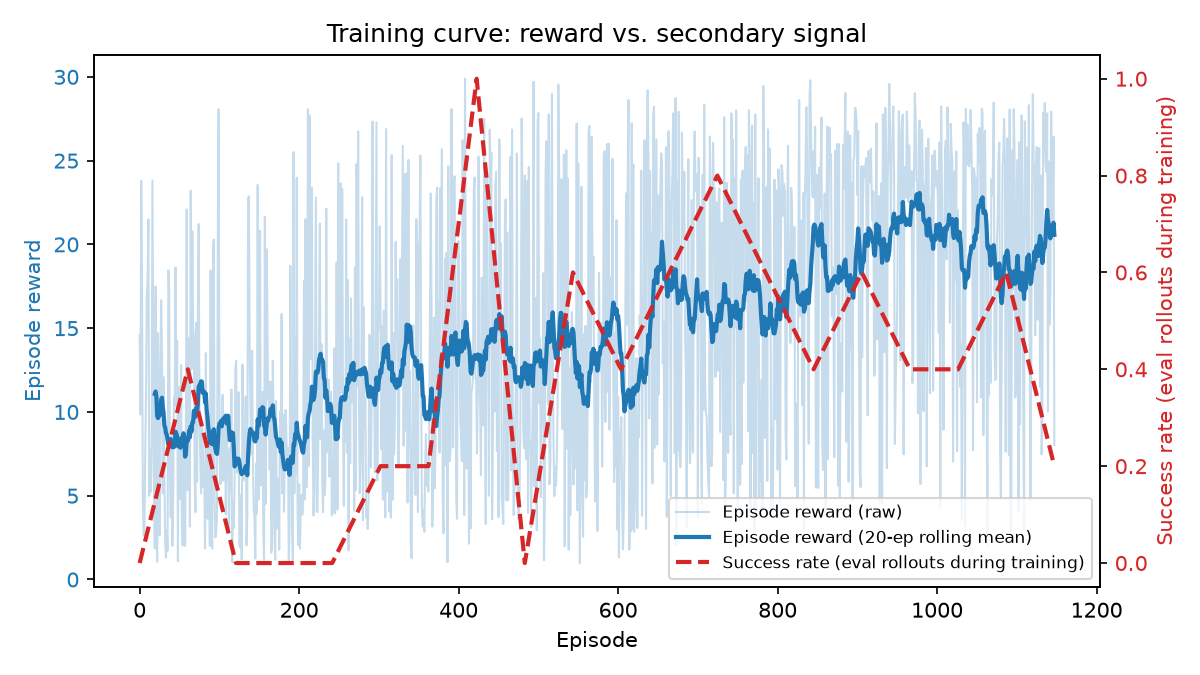

In [24]:
import pandas as pd

monitor_df = pd.read_csv("artifacts/monitor.csv", skiprows=1)
secondary = [h["success_rate"] for h in diag_callback.history]

plot_training_curve(
    monitor_df["r"].tolist(),
    secondary=secondary,
    secondary_label="Success rate (eval rollouts during training)",
    save_path="artifacts/training_curve.png",
)
from IPython.display import Image as IPImage
IPImage("artifacts/training_curve.png")

In [25]:
frames = record_rollout(model, eval_env, n_episodes=1, deterministic=True)
save_gif(frames, "artifacts/rollout.gif", fps=10)
save_mp4(frames, "artifacts/rollout.mp4", fps=10)
print(f"Recorded {len(frames)} frames.")

Recorded 16 frames.


In [26]:
write_results(
    "artifacts/results.json",
    summary,
    algo="dqn",
    env_id=MANDATORY_ENV_ID,
    total_timesteps=MANDATORY_TIMESTEP_BUDGET,
    seed=0,
)
print("Wrote artifacts/results.json")
print(summary)

Wrote artifacts/results.json
{'n_episodes': 20, 'mean_reward': 20.023583177295734, 'collision_rate': 0.6, 'success_rate': 0.4, 'mean_survival_steps': 22.55}


### Mandatory task submission checklist

- [ ] `run_diagnostics_self_check()` prints `ALL CHECKS PASSED`
- [ ] `artifacts/dqn_highway.zip` saved
- [ ] `artifacts/training_curve.png` saved (reward **and** secondary signal visible)
- [ ] `artifacts/rollout.gif` (and/or `.mp4`) saved
- [ ] `artifacts/results.json` saved
- [ ] Notebook committed (with the `AUTOGRADER_EXTRACT_START/END` markers around the `diagnostics`
      cell left intact — do not delete or rename them), PR opened + reviewed + merged, submitted via
      Gradescope (see lab sheet §5, Phase 5–6)

---
## OPTIONAL EXTENSIONS (ungraded — take home)

Not autograded, not required for the mandatory 40 marks. Pick any that interest you — several map
directly onto techniques you may want for your **Assignment 2** RL track.

1. **PPO on continuous control** — Use `train_ppo(...)` (defined above) on `racetrack-v0` (continuous
   steering/throttle). Compare PPO's clipped-objective stability (slide 42) against your DQN's
   training curve.
2. **Potential-based reward shaping on `parking-v0`** — Implement the `shaping` cell above
   (`run_shaping_self_check()`), wrap `parking-v0`'s sparse reward with `shape_reward(...)`, and show
   it trains faster than the unshaped baseline.
3. **Reward hacking, deliberately** — Edit a copy of `MANDATORY_ENV_CONFIG` so one reward term
   dominates (e.g. set `collision_reward=0`). Train briefly, and show how your secondary diagnostic
   signal (not reward!) reveals the degenerate behaviour (slides 53–55).
4. **Double DQN ablation** — Compare `target_update_interval` settings, or wrap SB3's Double-DQN-style
   target handling explicitly; plot overestimation of Q-values vs. true return (slide 28).
5. **State-of-the-art extensions (for your Assignment 2 proposal):**
   - *Dueling / Prioritized Experience Replay* via `sb3-contrib`'s `QRDQN`, comparing sample efficiency.
   - *Recurrent policies* (`sb3-contrib`'s `RecurrentPPO`) on a partially-observable scenario
     (reduced `vehicles_count` + occlusion) to handle non-Markovian observations.
   - *Multi-agent-flavoured scenarios* — `intersection-v0` or `roundabout-v0` with reward shaping
     for safe merging.
   - *Self-play / curriculum* — progressively increase `vehicles_count` across training stages,
     echoing the self-play scaling result referenced on lecture slide 44.
